In [1]:
import pandas as pd
import matplotlib.pyplot as plt             
import seaborn as sns               
import numpy as np

In [2]:
df  = pd.read_excel(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\fish.xlsx")
df

,Bream,242,23.2,25.4,30,38.4,13.4
0,Bream,290.0,24.0,26.3,31.2,40.0,13.8
1,Bream,340.0,23.9,26.5,31.1,39.8,15.1
2,Bream,363.0,26.3,29.0,33.5,38.0,13.3
3,Bream,430.0,26.5,29.0,34.0,36.6,15.1
4,Bream,450.0,26.8,29.7,34.7,39.2,14.2
...,...,...,...,...,...,...,...
79,Pike,950.0,48.3,51.7,55.1,16.2,11.2
80,Pike,1250.0,52.0,56.0,59.7,17.9,11.7
81,Pike,1600.0,56.0,60.0,64.0,15.0,9.6
82,Pike,1550.0,56.0,60.0,64.0,15.0,9.6


In [3]:
df.isnull().sum()

Bream    0
242      0
23.2     0
25.4     0
30       0
38.4     0
13.4     0
dtype: int64

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Bream   84 non-null     str    
 1   242     84 non-null     float64
 2   23.2    84 non-null     float64
 3   25.4    84 non-null     float64
 4   30      84 non-null     float64
 5   38.4    84 non-null     float64
 6   13.4    84 non-null     float64
dtypes: float64(6), str(1)
memory usage: 4.7 KB


In [6]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["Bream"] = le.fit_transform(df["Bream"])

In [8]:
X = df.drop("Bream", axis=1)
Y= df["Bream"]

In [19]:
from sklearn.preprocessing import MinMaxScaler
minmax = MinMaxScaler(feature_range=(0,1))
x = minmax.fit_transform(X)
x = pd.DataFrame(x, columns=X.columns)
x.describe()

,242,23.2,25.4,30,38.4,13.4
count,84.000000,84.000000,84.000000,84.000000,84.000000,84.000000
mean,0.263041,0.363946,0.369536,0.390859,0.448452,0.562098
std,0.231908,0.228331,0.228538,0.232029,0.345038,0.287754
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.072727,0.201710,0.208022,0.222902,0.079167,0.293919
50%,0.236364,0.385312,0.392724,0.423951,0.413333,0.675676
75%,0.398485,0.471328,0.488806,0.522290,0.824167,0.810811
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [20]:
x =  pd.concat([x,Y], axis =1)
x

,242,23.2,25.4,30,38.4,13.4,Bream
0,0.175758,0.295775,0.307836,0.356643,0.850000,0.689189,0
1,0.206061,0.293763,0.311567,0.354895,0.843333,0.864865,0
2,0.220000,0.342052,0.358209,0.396853,0.783333,0.621622,0
3,0.260606,0.346076,0.358209,0.405594,0.736667,0.864865,0
4,0.272727,0.352113,0.371269,0.417832,0.823333,0.743243,0
...,...,...,...,...,...,...,...
79,0.575758,0.784708,0.781716,0.774476,0.056667,0.337838,1
80,0.757576,0.859155,0.861940,0.854895,0.113333,0.405405,1
81,0.969697,0.939638,0.936567,0.930070,0.016667,0.121622,1
82,0.939394,0.939638,0.936567,0.930070,0.016667,0.121622,1


In [21]:
x.to_csv("FishData_Cleaned.csv", index=False)

In [22]:
df1 = pd.read_csv("FishData_Cleaned.csv")
df1

,242,23.2,25.4,30,38.4,13.4,Bream
0,0.175758,0.295775,0.307836,0.356643,0.850000,0.689189,0
1,0.206061,0.293763,0.311567,0.354895,0.843333,0.864865,0
2,0.220000,0.342052,0.358209,0.396853,0.783333,0.621622,0
3,0.260606,0.346076,0.358209,0.405594,0.736667,0.864865,0
4,0.272727,0.352113,0.371269,0.417832,0.823333,0.743243,0
...,...,...,...,...,...,...,...
79,0.575758,0.784708,0.781716,0.774476,0.056667,0.337838,1
80,0.757576,0.859155,0.861940,0.854895,0.113333,0.405405,1
81,0.969697,0.939638,0.936567,0.930070,0.016667,0.121622,1
82,0.939394,0.939638,0.936567,0.930070,0.016667,0.121622,1


Text(0, 0.5, 'Euclidean Distance')

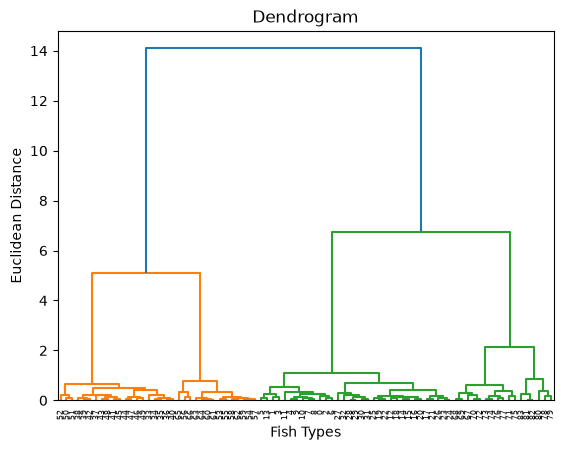

In [23]:
import scipy.cluster.hierarchy as sch  
dendrogram = sch.dendrogram(sch.linkage(df1, method="ward"))
plt.title("Dendrogram")
plt.xlabel("Fish Types")
plt.ylabel("Euclidean Distance")

In [24]:
from sklearn.cluster import AgglomerativeClustering
alg = AgglomerativeClustering(n_clusters=4, linkage="ward")
hca = alg.fit_predict(df1)

In [26]:
from sklearn.metrics import silhouette_score
print("silhouette score:", silhouette_score(df1,hca))

silhouette score: 0.7875393104329097
